In [2]:
import os
import csv
import math
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

In [3]:
students = []

subjects = [
    "Maths",
    "Physics",
    "Chemistry",
    "English",
    "Computer"
]

In [4]:
def calculate_result(marks):
    total = sum(marks)
    percentage = total / len(marks)

    if percentage >= 90:
        grade = "A+"
    elif percentage >= 80:
        grade = "A"
    elif percentage >= 70:
        grade = "B"
    elif percentage >= 60:
        grade = "C"
    elif percentage >= 50:
        grade = "D"
    elif percentage >= 40:
        grade = "E"
    else:
        grade = "F"

    if all(mark >= 40 for mark in marks):
        result = "PASS"
    else:
        result = "FAIL"

    return total, percentage, grade, result

In [5]:
def calculate_attendance(present_days, total_days):
    if total_days == 0:
        return 0

    percentage = (present_days / total_days) * 100
    return math.ceil(percentage)

In [6]:
available_clubs = [
    "Coding",
    "Robotics",
    "Sports",
    "Music"
]

def check_club(club):
    return club in available_clubs

In [7]:
club = input("Enter club name: ")

if check_club(club):
    print("Club is available.")
else:
    print("Club is not available.")

Enter club name: Coding
Club is available.


In [8]:
def add_student():

    print("\n========== ADD STUDENT ==========")

    roll = int(input("Enter Roll Number: "))
    name = input("Enter Student Name: ")
    branch = input("Enter Branch: ")
    semester = int(input("Enter Semester: "))
    email = input("Enter Email: ")
    mobile = input("Enter Mobile Number: ")

    print("\n----- Enter Marks -----")

    marks = []

    for subject in subjects:
        mark = float(input(f"Enter {subject} marks: "))
        marks.append(mark)

    total, percentage, grade, result = calculate_result(marks)

    print("\n----- Attendance -----")

    total_days = int(input("Enter Total Working Days: "))
    present_days = int(input("Enter Present Days: "))

    attendance = calculate_attendance(
        present_days,
        total_days
    )

    print("\n----- Activities -----")

    club = input("Enter Club Name: ")
    hostel = input("Hostel Required? (Yes/No): ")

    student = {
        "Roll": roll,
        "Name": name,
        "Branch": branch,
        "Semester": semester,
        "Email": email,
        "Mobile": mobile,

        "Maths": marks[0],
        "Physics": marks[1],
        "Chemistry": marks[2],
        "English": marks[3],
        "Computer": marks[4],

        "Total": total,
        "Percentage": percentage,
        "Grade": grade,
        "Result": result,

        "Total_Days": total_days,
        "Present_Days": present_days,
        "Attendance": attendance,

        "Club": club,
        "Hostel": hostel
    }

    students.append(student)

    print("\nStudent added successfully!")

In [9]:
def display_student(student):

    print("\n" + "=" * 50)
    print("              STUDENT DETAILS")
    print("=" * 50)

    print(f"Roll Number : {student['Roll']}")
    print(f"Name        : {student['Name']}")
    print(f"Branch      : {student['Branch']}")
    print(f"Semester    : {student['Semester']}")
    print(f"Email       : {student['Email']}")
    print(f"Mobile      : {student['Mobile']}")

    print("\n----- Academic Performance -----")

    for subject in subjects:
        print(f"{subject:<12}: {student[subject]}")

    print(f"\nTotal       : {student['Total']}")
    print(f"Percentage  : {student['Percentage']:.2f}%")
    print(f"Grade       : {student['Grade']}")
    print(f"Result      : {student['Result']}")

    print("\n----- Attendance -----")

    print(f"Total Days  : {student['Total_Days']}")
    print(f"Present     : {student['Present_Days']}")
    print(f"Attendance  : {student['Attendance']}%")

    print("\n----- Activities -----")

    print(f"Club        : {student['Club']}")
    print(f"Hostel      : {student['Hostel']}")

    print("=" * 50)

In [10]:
def view_students():

    if len(students) == 0:
        print("\nNo students found.")
        return

    for student in students:
        display_student(student)

In [11]:
def search_student():

    roll = int(input("Enter Roll Number to search: "))

    for student in students:

        if student["Roll"] == roll:
            display_student(student)
            return

    print("Student not found.")

In [12]:
def update_student():

    roll = int(input("Enter Roll Number to update: "))

    for student in students:

        if student["Roll"] == roll:

            print("\nStudent found.")

            student["Name"] = input(
                "Enter new name: "
            )

            student["Branch"] = input(
                "Enter new branch: "
            )

            student["Semester"] = int(
                input("Enter new semester: ")
            )

            print("Student updated successfully.")
            return

    print("Student not found.")

In [13]:
def delete_student():

    roll = int(input("Enter Roll Number to delete: "))

    for student in students:

        if student["Roll"] == roll:

            students.remove(student)

            print("Student deleted successfully.")
            return

    print("Student not found.")

In [14]:
CSV_FILE = "student_management.csv"


def save_to_csv():

    if len(students) == 0:
        print("No student data available.")
        return

    df = pd.DataFrame(students)

    df.to_csv(
        CSV_FILE,
        index=False
    )

    print("\nData saved to CSV successfully.")

In [15]:
def load_from_csv():

    global students

    if os.path.exists(CSV_FILE):

        df = pd.read_csv(CSV_FILE)

        students = df.to_dict(
            orient="records"
        )

        print("Student data loaded successfully.")

    else:
        print("CSV file does not exist.")

In [16]:
def numpy_analysis():

    if len(students) == 0:
        print("No data available.")
        return

    marks = np.array([
        [
            s["Maths"],
            s["Physics"],
            s["Chemistry"],
            s["English"],
            s["Computer"]
        ]
        for s in students
    ])

    print("\n========== NUMPY ANALYSIS ==========")

    print("Marks Array:")
    print(marks)

    totals = np.sum(marks, axis=1)

    averages = np.mean(marks, axis=1)

    print("\nTotal Marks:")
    print(totals)

    print("\nAverage Marks:")
    print(np.round(averages, 2))

In [17]:
def pandas_analysis():

    if not os.path.exists(CSV_FILE):
        print("First save student data to CSV.")
        return

    df = pd.read_csv(CSV_FILE)

    print("\n========== PANDAS ANALYSIS ==========")

    print("\nStudent Data:")
    print(df)

    print("\nSubject-wise Average:")

    print(
        df[subjects].mean()
    )

    print("\nHighest Marks:")

    print(
        df[subjects].max()
    )

    print("\nLowest Marks:")

    print(
        df[subjects].min()
    )

In [18]:
def scipy_analysis():

    if len(students) == 0:
        print("No data available.")
        return

    percentages = np.array([
        s["Percentage"]
        for s in students
    ])

    print("\n========== SCIPY ANALYSIS ==========")

    print(
        "Mean:",
        np.mean(percentages)
    )

    print(
        "Median:",
        np.median(percentages)
    )

    print(
        "Standard Deviation:",
        np.std(percentages, ddof=1)
    )

    print(
        "Variance:",
        np.var(percentages, ddof=1)
    )

    print(
        "Skewness:",
        stats.skew(percentages)
    )

In [19]:
def visualization():

    if not os.path.exists(CSV_FILE):
        print("First save student data to CSV.")
        return

    df = pd.read_csv(CSV_FILE)

    plt.figure(figsize=(10, 6))

    df[subjects].mean().plot(
        kind="bar"
    )

    plt.title("Average Marks by Subject")
    plt.xlabel("Subjects")
    plt.ylabel("Average Marks")

    plt.tight_layout()
    plt.show()

In [20]:
def attendance_chart():

    if not os.path.exists(CSV_FILE):
        print("First save student data.")
        return

    df = pd.read_csv(CSV_FILE)

    plt.figure(figsize=(10, 6))

    plt.bar(
        df["Name"],
        df["Attendance"]
    )

    plt.title("Student Attendance")
    plt.xlabel("Student")
    plt.ylabel("Attendance %")

    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

In [21]:
def main_menu():

    load_from_csv()

    while True:

        print("\n")
        print("=" * 55)
        print("        STUDENT MANAGEMENT SYSTEM")
        print("=" * 55)

        print("1. Add Student")
        print("2. View All Students")
        print("3. Search Student")
        print("4. Update Student")
        print("5. Delete Student")
        print("6. Save Data to CSV")
        print("7. NumPy Analysis")
        print("8. Pandas Analysis")
        print("9. SciPy Statistical Analysis")
        print("10. Student Performance Graph")
        print("11. Attendance Graph")
        print("0. Exit")

        choice = input("\nEnter your choice: ")

        if choice == "1":
            add_student()

        elif choice == "2":
            view_students()

        elif choice == "3":
            search_student()

        elif choice == "4":
            update_student()

        elif choice == "5":
            delete_student()

        elif choice == "6":
            save_to_csv()

        elif choice == "7":
            numpy_analysis()

        elif choice == "8":
            pandas_analysis()

        elif choice == "9":
            scipy_analysis()

        elif choice == "10":
            visualization()

        elif choice == "11":
            attendance_chart()

        elif choice == "0":

            save_to_csv()

            print("\nThank you for using Student Management System.")

            break

        else:
            print("\nInvalid choice. Try again.")

CSV file does not exist.


        STUDENT MANAGEMENT SYSTEM
1. Add Student
2. View All Students
3. Search Student
4. Update Student
5. Delete Student
6. Save Data to CSV
7. NumPy Analysis
8. Pandas Analysis
9. SciPy Statistical Analysis
10. Student Performance Graph
11. Attendance Graph
0. Exit

Enter your choice: 1

========== ADD STUDENT ==========
Enter Roll Number: 101
Enter Student Name: Aryan
Enter Branch: Computer Engineering
Enter Semester: 5
Enter Email: aryan@example.com
Enter Mobile Number: 9876543210

----- Enter Marks -----
Enter Maths marks: 92
Enter Physics marks: 88
Enter Chemistry marks: 75
Enter English marks: 80
Enter Computer marks: 90

----- Attendance -----
Enter Total Working Days: 100
Enter Present Days: 92

----- Activities -----
Enter Club Name: Coding
Hostel Required? (Yes/No): No

Student added successfully!


        STUDENT MANAGEMENT SYSTEM
1. Add Student
2. View All Students
3. Search Student
4. Update Student
5. Delete Student
6. Save Data to CSV
7. Nu

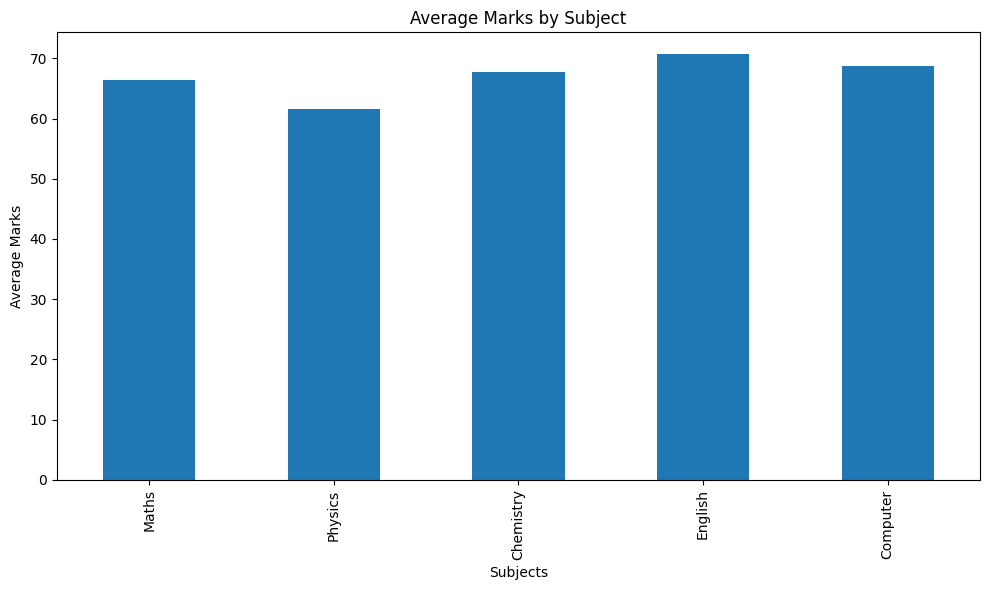



        STUDENT MANAGEMENT SYSTEM
1. Add Student
2. View All Students
3. Search Student
4. Update Student
5. Delete Student
6. Save Data to CSV
7. NumPy Analysis
8. Pandas Analysis
9. SciPy Statistical Analysis
10. Student Performance Graph
11. Attendance Graph
0. Exit

Enter your choice: 11


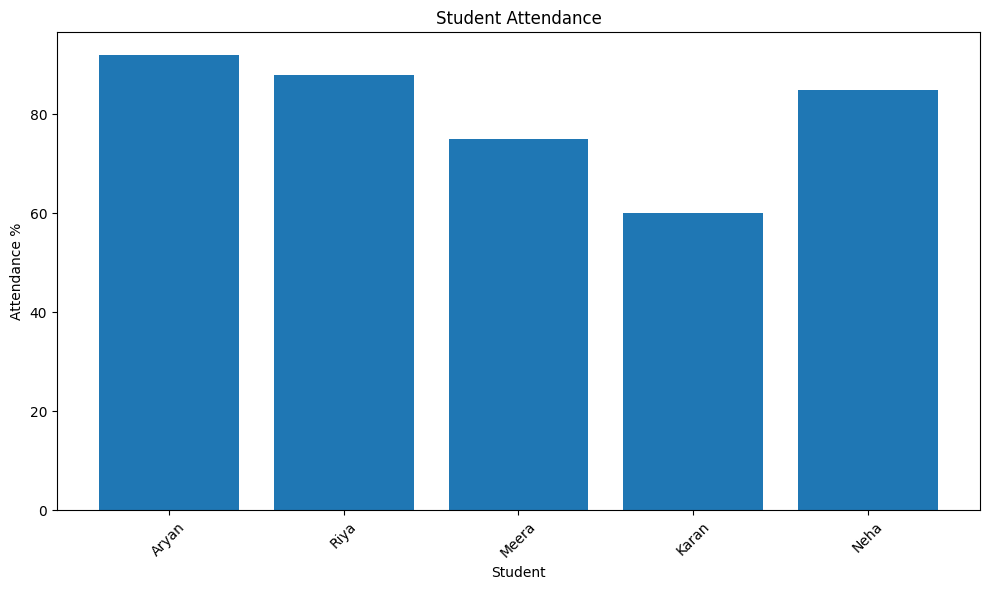



        STUDENT MANAGEMENT SYSTEM
1. Add Student
2. View All Students
3. Search Student
4. Update Student
5. Delete Student
6. Save Data to CSV
7. NumPy Analysis
8. Pandas Analysis
9. SciPy Statistical Analysis
10. Student Performance Graph
11. Attendance Graph
0. Exit

Enter your choice: 0

Data saved to CSV successfully.

Thank you for using Student Management System.


In [22]:
main_menu()

In [23]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [24]:
df = pd.read_csv("student_placement_knn_100_students.csv")

df.head()

,Student_ID,Year,Branch,Gender,10th_Percentage,12th_Percentage,CGPA,Backlogs,Coding_Skill_Marks,Aptitude_Marks,Certifications,Internships,Communication_Marks,Placed
0,STU1005,2024,Computer Engineering,Male,87.1,81.1,7.89,0,38,60,3,1,4.0,Yes
1,STU1006,2024,Computer Engineering,Male,87.6,96.5,8.08,1,55,43,1,0,6.2,Yes
2,STU1008,2024,IT,Male,91.0,88.4,8.89,0,52,46,1,1,7.5,Yes
3,STU1014,2024,IT,Male,96.2,84.2,7.47,2,34,56,0,0,4.3,No
4,STU1016,2024,ECE,Male,72.3,73.7,6.80,0,42,52,1,1,3.8,No


In [25]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:


Student_ID             0
Year                   0
Branch                 0
Gender                 0
10th_Percentage        0
12th_Percentage        0
CGPA                   0
Backlogs               0
Coding_Skill_Marks     0
Aptitude_Marks         0
Certifications         0
Internships            0
Communication_Marks    0
Placed                 0
dtype: int64

Duplicate rows:
0


In [26]:
df = df.drop_duplicates()

df = df.dropna()

print("After cleaning:", df.shape)

After cleaning: (100, 14)


In [27]:
X = df.drop(columns=["Student_ID", "Placed"])

y = df["Placed"]

print("Input features:")
print(X.columns)

print("\nTarget:")
print(y.head())

Input features:
Index(['Year', 'Branch', 'Gender', '10th_Percentage', '12th_Percentage',
       'CGPA', 'Backlogs', 'Coding_Skill_Marks', 'Aptitude_Marks',
       'Certifications', 'Internships', 'Communication_Marks'],
      dtype='str')

Target:
0    Yes
1    Yes
2    Yes
3     No
4     No
Name: Placed, dtype: str


In [28]:
X = pd.get_dummies(X, columns=["Branch", "Gender"], dtype=int)

X.head()

,Year,10th_Percentage,12th_Percentage,CGPA,Backlogs,Coding_Skill_Marks,Aptitude_Marks,Certifications,Internships,Communication_Marks,Branch_Civil,Branch_Computer Engineering,Branch_ECE,Branch_Electrical,Branch_IT,Branch_Mechanical,Gender_Female,Gender_Male
0,2024,87.1,81.1,7.89,0,38,60,3,1,4.0,0,1,0,0,0,0,0,1
1,2024,87.6,96.5,8.08,1,55,43,1,0,6.2,0,1,0,0,0,0,0,1
2,2024,91.0,88.4,8.89,0,52,46,1,1,7.5,0,0,0,0,1,0,0,1
3,2024,96.2,84.2,7.47,2,34,56,0,0,4.3,0,0,0,0,1,0,0,1
4,2024,72.3,73.7,6.80,0,42,52,1,1,3.8,0,0,1,0,0,0,0,1


In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training students:", len(X_train))
print("Testing students:", len(X_test))

Training students: 70
Testing students: 30


In [30]:
# Scale the features before using KNN
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")


Feature scaling completed.


In [31]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [32]:
y_pred = knn.predict(X_test_scaled)

print("Predicted results:")
print(y_pred)

Predicted results:
['No' 'Yes' 'Yes' 'No' 'No' 'No' 'No' 'Yes' 'No' 'No' 'Yes' 'No' 'No'
 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'Yes'
 'No' 'No' 'Yes' 'Yes']


In [33]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(results)

   Actual Predicted
0      No        No
1      No       Yes
2     Yes       Yes
3      No        No
4      No        No
5     Yes        No
6      No        No
7     Yes       Yes
8      No        No
9      No        No
10    Yes       Yes
11    Yes        No
12     No        No
13     No       Yes
14    Yes       Yes
15    Yes       Yes
16     No        No
17     No       Yes
18    Yes       Yes
19     No        No
20     No        No
21     No        No
22    Yes       Yes
23    Yes        No
24     No        No
25     No       Yes
26    Yes        No
27    Yes        No
28    Yes       Yes
29     No       Yes


In [34]:
accuracy = accuracy_score(y_test, y_pred)

print("KNN Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

KNN Accuracy: 0.6666666666666666
Accuracy Percentage: 66.66666666666666 %


In [35]:
new_student = pd.DataFrame({
    "Year": [2026],
    "Branch": ["Computer Engineering"],
    "Gender": ["Male"],
    "10th_Percentage": [85],
    "12th_Percentage": [82],
    "CGPA": [8.4],
    "Backlogs": [0],
    "Coding_Skill_Marks": [85],
    "Aptitude_Marks": [78],
    "Certifications": [2],
    "Internships": [2],
    "Communication_Marks": [8]
})

In [36]:
# Prepare the new student's data in the same format used for training
new_student_encoded = pd.get_dummies(
    new_student,
    columns=["Branch", "Gender"],
    dtype=int
)

# Ensure the new student's columns and order match the training data
new_student_encoded = new_student_encoded.reindex(
    columns=X.columns,
    fill_value=0
)

# Apply the same scaler that was fitted on the training data
new_student_scaled = scaler.transform(new_student_encoded)

# Predict the placement result
prediction = knn.predict(new_student_scaled)
print("Predicted placement value:", prediction[0])

# Display a readable result (assuming 1 = Placed and 0 = Not Placed)
if prediction[0] == 1:
    print("Prediction: Placed")
elif prediction[0] == 0:
    print("Prediction: Not Placed")
else:
    print("Prediction label:", prediction[0])


Predicted placement value: Yes
Prediction label: Yes
